# Arms 0 and 5 on the Platform

The notebook shows two arms of an experiment on your data and your engine:

- **arm 0** — random search: B random rules from the grammar, structure and numbers are random;
- **arm 5** — GP (DEAP) builds structures, Optuna tunes the numbers; the same budget B of backtests.

Order of operations:
1. Candles are fetched from the platform store via `OHLCVDataProvider`, the same source as the backtest.
2. **Engine parity:** three rules are run through your `BacktestEngine` and through the fast vector engine (`lab.Ledger`); the equity curves must match.
3. The search for both arms runs in the fast engine: a backtest there takes milliseconds, on the platform it takes seconds (section 2 measures this).
4. The rule each arm submits is re-run through `BacktestEngine` over the full period; hold-out window metrics are taken from its equity curve.

Bar windows: `| train 70 % | validation 30 % |` — this is the search window (first 75 % of bars), followed by the hold-out window (last 25 %), which the search never sees.

## 0. Setup

Run the notebook in the same environment as the backend: the candle provider needs the database and its environment variables. Required packages: `deap optuna numpy pandas matplotlib`.

`CODE_DIR` — the folder containing `strategy_gp.py`, `lab.py`, `arm0_random.py`, `demo_gp_optuna.py`, `platform_bridge.py`, `rule_strategy.py`; `REPO_ROOT` — the folder that contains the `app` package.

In [4]:
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

REPO_ROOT = Path.cwd().parent      # the folder that contains the platform package `app`
CODE_DIR = Path.cwd()              # the folder with strategy_gp.py, lab.py, platform_bridge.py, ...
for path in (REPO_ROOT, CODE_DIR):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import arm0_random
import app.strategies.genetic.demo_gp_optuna as arm5
import app.strategies.genetic.llm.lab as lab
import app.strategies.genetic.platform_bridge as pb
import app.strategies.genetic.strategy_gp as sg
from app.strategies.genetic.rule_strategy import RuleStrategy
from app.data.data_provider import GapsFoundError, OHLCVDataProvider

pd.set_option("display.max_colwidth", 140)

F:\Університет\AlphaMiner\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Parameters. One seed is enough for a demo; for the experiment you need at least five, and arms are compared pairwise by seed. For minute bars use a shorter period: the bar count grows 60×.

In [5]:
SYMBOL, EXCHANGE, TIMEFRAME = "BTC/USDT", "binance", "1h"
START = datetime(2022, 1, 1, tzinfo=timezone.utc)
END = datetime(2026, 10, 1, tzinfo=timezone.utc)
HOLDOUT_FRACTION = 0.25          # the last quarter of the bars: never seen by the search
BUDGET = 2000                    # backtests per arm and seed (B), the same for both arms
K = 10                           # Optuna trials per GP structure
POP = 30                         # GP population
SEEDS = [0]                      # one seed for a demo; at least five for the experiment
PLATFORM_SEEDS = SEEDS[:1]       # rules handed in under these seeds are re-run on the platform engine
MONEY = 10_000.0
COST_BPS = 12                    # fee + slippage per side in the fast engine

lab.BARS_PER_YEAR = pb.BARS_PER_YEAR[TIMEFRAME]
lab.COST_BPS = COST_BPS
STRATEGY = dict(symbol=SYMBOL, exchange=EXCHANGE, timeframe=TIMEFRAME)


def make_provider(strategy, start=START, end=END):
    """A fresh candle provider, built the way the backtest Celery task builds it."""
    return OHLCVDataProvider(strategy, start, end, EXCHANGE, SYMBOL, TIMEFRAME)

## 1. Candles

If the store reports gaps (`GapsFoundError`), run the backfill cell below and re-run this one.

In [7]:
probe = RuleStrategy(**STRATEGY)
try:
    data, stamps = pb.bars_from_provider(make_provider(probe), probe)
except GapsFoundError as err:
    print("The candle store has gaps:", err.gaps)
    raise

N = len(data["close"])
N_SEARCH = int(N * (1 - HOLDOUT_FRACTION))
N_TRAIN = int(N_SEARCH * lab.TRAIN_FRACTION)
print(f"{N} bars, {stamps[0]} .. {stamps[-1]}")
print(f"train {N_TRAIN} bars, validation {N_SEARCH - N_TRAIN}, hold-out {N - N_SEARCH} (from {stamps[N_SEARCH]})")

41615 bars, 2022-01-01 00:00:00+00:00 .. 2026-09-30 23:00:00+00:00
train 21847 bars, validation 9364, hold-out 10404 (from 2025-07-24 12:00:00+00:00)


In [ ]:
# Only if the cell above reported gaps: the call the backfill_ohlcv Celery task makes, run here directly.
# from app.data.service.backfill_service import BackfillService
# BackfillService(EXCHANGE).run(START, END, SYMBOL, TIMEFRAME)

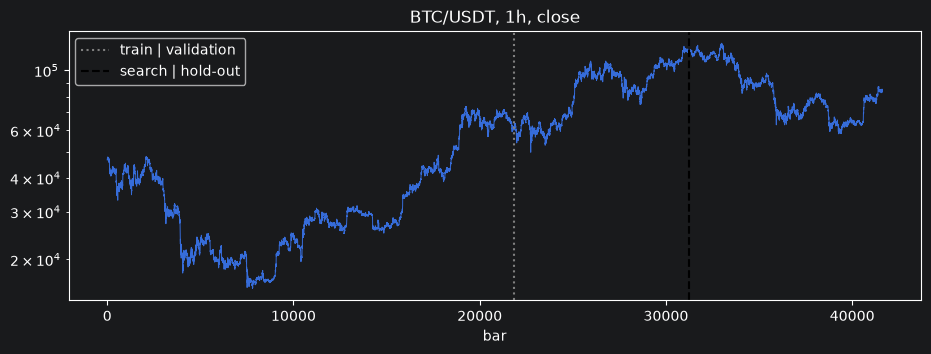

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(data["close"], lw=0.7)
ax.axvline(N_TRAIN, color="grey", ls=":", label="train | validation")
ax.axvline(N_SEARCH, color="black", ls="--", label="search | hold-out")
ax.set_yscale("log")
ax.set_title(f"{SYMBOL}, {TIMEFRAME}, close")
ax.set_xlabel("bar")
ax.legend()
plt.show()

## 2. Engine Parity

Three classic rules are run through your `BacktestEngine` (via the `RuleStrategy` adapter) and through the fast engine over one short period. Your engine currently runs without commissions (`BacktestEngine.run` creates `BacktestExecutionEngine()` with `Commission(0, 0)`), so the fast engine here also runs without costs.

`max equity gap %` should be near zero and the number of closed trades should match. If not, search results do not transfer to your engine: the cause of the discrepancy must be found first.

In [10]:
PARITY_START = datetime(2026, 6, 1, tzinfo=timezone.utc)
PARITY_RULES = [sg.CLASSICS[name] for name in ("rsi_reversion", "ma_cross", "donchian_breakout")]

parity_data, _ = pb.bars_from_provider(make_provider(probe, PARITY_START), probe)
rows = []
for rule in PARITY_RULES:
    result, seconds = pb.run_platform(rule, lambda s: make_provider(s, PARITY_START), MONEY, **STRATEGY)
    rows.append({**pb.parity(parity_data, rule, result, MONEY), "platform, s": round(seconds, 1)})

started = time.perf_counter()
for rule in PARITY_RULES:
    pb.fast_equity(parity_data, rule)
fast_ms = (time.perf_counter() - started) / len(PARITY_RULES) * 1000
print(f"fast engine: {fast_ms:.1f} ms per backtest on {len(parity_data['close'])} bars")
pd.DataFrame(rows)

fast engine: 0.6 ms per backtest on 2928 bars


,rule,bars,bars platform,closed trades fast,closed trades platform,profit % fast,profit % platform,max equity gap %,"platform, s"
0,"long_flat(osc_below(rsi(close, 14), 30), osc_above(rsi(close, 14), 70))",2928,2928,39,39,11.891138,11.891138,1.554312e-13,1.5
1,"long_flat(cross_up(sma(close, 20), sma(close, 100)), cross_up(sma(close, 100), sma(close, 20)))",2928,2928,17,17,5.159721,5.159721,2.664535e-13,0.7
2,"long_flat(gt(close, lag(rmax(high, 55), 1)), gt(lag(rmin(low, 20), 1), close))",2928,2928,20,20,9.246009,9.246009,1.776357e-13,0.7


## 3. Arm 0: Random Search

B random rules: structure from the same typed generator as GP, numbers are random (windows are log-uniform). This is the null model: if arm 5 does not beat it on the hold-out window, the search adds nothing beyond randomness.

In [11]:
runs = {}
for seed in SEEDS:
    started = time.perf_counter()
    ledger = arm0_random.random_search(data, BUDGET, seed=seed, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("0: random", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 0, seed {seed}: {ledger.used} backtests, {minutes:.1f} min")

arm 0, seed 0: 2000 backtests, 0.2 min


## 4. Arm 5: GP + Optuna

GP (DEAP, typed trees) builds structures, Optuna tunes the numbers for each structure in K trials on train. Each trial is one backtest drawn from the same budget B.

In [12]:
for seed in SEEDS:
    started = time.perf_counter()
    ledger, generations = arm5.evolve(data, seed=seed, budget=BUDGET, pop_size=POP, k=K, n_search=N_SEARCH)
    minutes = (time.perf_counter() - started) / 60
    runs[("5: GP + Optuna", seed)] = {"ledger": ledger, "minutes": minutes}
    print(f"arm 5, seed {seed}: {generations} generations, {ledger.used} backtests, {minutes:.1f} min")

arm 5, seed 0: 18 generations, 2000 backtests, 0.3 min


## 5. What Each Arm Submits (fast engine)

The finalist is selected identically for both arms (`lab.select_final`): from the 10 rules with the best train Sharpe, the rule with the best validation score Q is chosen, provided it passes the trade count and drawdown thresholds and stress probes. The hold-out Sharpe is computed after `COST_BPS` costs.

DSR — deflated Sharpe against the arm's trial log in two conventions: `null V` — null-hypothesis variance 1/T over behaviourally distinct rules, `ledger V` — variance over all trials.

In [13]:
summary = pd.DataFrame([{"arm": arm, "seed": seed, "minutes": round(run["minutes"], 1),
                         **lab.summarize(data, run["ledger"])}
                        for (arm, seed), run in runs.items()])
summary

,arm,seed,minutes,structures,rules,budget used,rule,train sharpe,train trades,val sharpe,val trades,Q,hold-out sharpe,hold-out trades,distinct tradable,DSR null V,N null V,DSR ledger V,N ledger V
0,0: random,0,0.2,1628,2000,2000,"long_flat(z_below(mom(bb_up(close, 468, 3.65), 48), -1.5), gt_v(sma_v(sma_v(volume, 468), 468), sma_v(sma_v(volume, 468), 2)))",0.798584,29,1.480318,14,1.329603,-1.863040,11,885,0.085047,885,0.0,2000
1,5: GP + Optuna,0,0.3,212,2000,2000,"long_flat(cross_up(high, close), gt(high, sma(lag(close, 15), 372)))",1.446171,29,0.534218,13,-0.020740,-0.996896,20,1172,0.110448,1172,0.0,2000


## 6. Finalists on Your Engine

Each arm's rule is run through `BacktestEngine` over the full period: the `long_flat` position depends on history, so the hold-out window cannot be run in isolation. Window metrics are computed from the slice of the equity curve.

- `platform hold-out` — your engine, no costs;
- `fast hold-out, no costs` — fast engine without costs, should match the previous column;
- `fast hold-out, costs` — fast engine with `COST_BPS`, closest to live trading;
- `engine: …` — metrics from `BacktestResult` itself over the full period. Its `sharpe_ratio` is annualised via √252, which is only correct for daily bars; Sharpe in the other columns uses `lab.BARS_PER_YEAR`.

In [14]:
checks, curves = [], {}
for _, s in summary.iterrows():
    if not isinstance(s["rule"], str) or s["seed"] not in PLATFORM_SEEDS:
        continue
    result, seconds = pb.run_platform(s["rule"], make_provider, MONEY, **STRATEGY)
    platform_curve = np.asarray(result.equity_curve, dtype=float) / MONEY
    free, _ = pb.fast_equity(data, s["rule"], 0.0)
    paid, _ = pb.fast_equity(data, s["rule"], COST_BPS)
    checks.append({
        "arm": s["arm"], "seed": s["seed"], "platform, s": round(seconds),
        **pb.prefixed("platform hold-out", pb.window_metrics(platform_curve, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, no costs", pb.window_metrics(free, N_SEARCH, lab.BARS_PER_YEAR)),
        **pb.prefixed("fast hold-out, costs", pb.window_metrics(paid, N_SEARCH, lab.BARS_PER_YEAR)),
        "engine: profit %": result.overall_profit_percent,
        "engine: max DD %": result.max_drawdown_percent,
        "engine: win rate %": result.win_rate_percent,
        "engine: sharpe (sqrt 252)": result.sharpe_ratio,
    })
    curves[(s["arm"], s["seed"])] = platform_curve

buy_and_hold = data["close"] / data["close"][0]
checks.append({"arm": "buy & hold",
               **pb.prefixed("platform hold-out", pb.window_metrics(buy_and_hold, N_SEARCH, lab.BARS_PER_YEAR))})
pd.DataFrame(checks)

,arm,seed,"platform, s",platform hold-out: return %,platform hold-out: sharpe,platform hold-out: max DD %,"fast hold-out, no costs: return %","fast hold-out, no costs: sharpe","fast hold-out, no costs: max DD %","fast hold-out, costs: return %","fast hold-out, costs: sharpe","fast hold-out, costs: max DD %",engine: profit %,engine: max DD %,engine: win rate %,engine: sharpe (sqrt 252)
0,0: random,0.0,31.0,-45.005508,-1.783085,49.584471,-45.005508,-1.783085,49.584471,-46.375891,-1.863040,50.544532,59.145978,53.790830,25.000000,0.0793
1,5: GP + Optuna,0.0,10.0,-25.711240,-0.839275,47.341089,-25.711240,-0.839275,47.341089,-29.186271,-0.996896,47.968211,43.115984,47.341089,32.786885,0.0849
2,buy & hold,NaN,NaN,-29.491062,-0.490464,53.742065,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


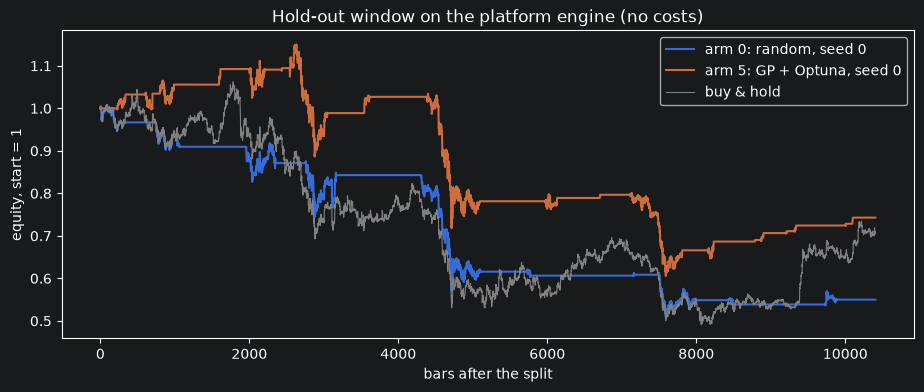

In [15]:
fig, ax = plt.subplots(figsize=(11, 4))
base = N_SEARCH - 1
for (arm, seed), curve in curves.items():
    ax.plot(curve[base:] / curve[base], label=f"arm {arm}, seed {seed}")
ax.plot(buy_and_hold[base:] / buy_and_hold[base], color="grey", lw=0.8, label="buy & hold")
ax.set_title("Hold-out window on the platform engine (no costs)")
ax.set_xlabel("bars after the split")
ax.set_ylabel("equity, start = 1")
ax.legend()
plt.show()

## 7. Selection Effect

Distribution of train Sharpe across all backtests for each arm. The submitted rule is the maximum over thousands of trials, so its train Sharpe is inflated; how much so is shown by the hold-out window. The spike at −1 comes from rules that trade less frequently than the `lab.MIN_TRADES` threshold.

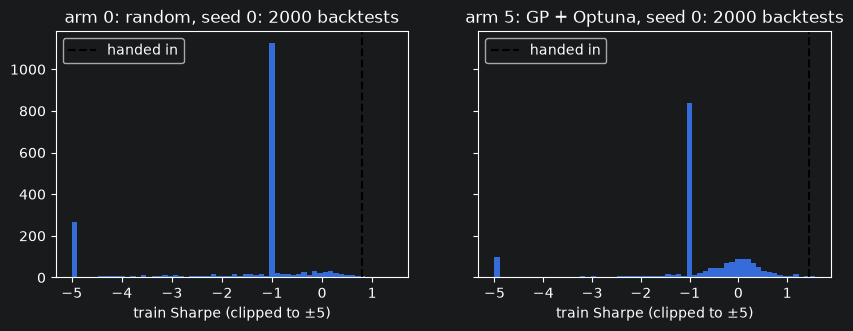

In [16]:
handed_in = summary.set_index(["arm", "seed"])["train sharpe"] if "train sharpe" in summary else None
fig, axes = plt.subplots(1, len(runs), figsize=(5 * len(runs), 3.2), sharey=True, squeeze=False)
for ax, ((arm, seed), run) in zip(axes[0], runs.items()):
    values = [lab.fitness(r) for r in run["ledger"].rows.values() if r["role"] != "probe"]
    ax.hist(np.clip(values, -5, 5), bins=60)
    if handed_in is not None and not pd.isna(handed_in.get((arm, seed))):
        ax.axvline(handed_in[(arm, seed)], color="black", ls="--", label="handed in")
        ax.legend()
    ax.set_title(f"arm {arm}, seed {seed}: {len(values)} backtests")
    ax.set_xlabel("train Sharpe (clipped to ±5)")
plt.show()

## How to Read the Results

- **Parity** (section 2): a near-zero equity gap and matching trade counts mean the fast engine reproduces yours and search conclusions transfer to the platform.
- **Arm comparison:** look at `hold-out sharpe` (section 5) and `fast hold-out, costs` (section 6), not at train — train is inflated by selection for both arms (section 7). If arm 5 does not beat arm 0 on the hold-out window, GP + Optuna provides no advantage over randomness on this data.
- **DSR** below 0.95 means the submitted rule's Sharpe is explained by the number of trials. With 2000 trials this is expected even for a real but weak effect.
- **One seed is illustrative.** For the experiment: `SEEDS = [0, 1, 2, 3, 4]`, equal `BUDGET`, pairwise arm comparison by seed.

Platform engine notes:
- `BacktestEngine.run` creates `BacktestExecutionEngine()` without commission or slippage, so platform profit is pre-cost;
- `BacktestResult.sharpe_ratio` is annualised via √252 for any timeframe: on hourly bars it is understated by roughly √(8760/252) ≈ 5.9×.